# HepatoClust, notebook 3 : DBSCAN, évaluation et analyse

Ce notebook teste une troisième famille de méthodes (DBSCAN, par densité), compare toutes les méthodes, puis vérifie pour la première fois les groupes obtenus avec la vraie catégorie des personnes. Il se termine par le profil médical des groupes et la conclusion du projet.

**Données utilisées** : fichiers du dossier resultats/, produits par les notebooks 1 et 2.
**La vraie catégorie n'est chargée qu'en partie 6**, après la construction de tous les clusters.

## Table des matières

0. [Imports et chargement des données](#partie0)
5. [Bonus : DBSCAN](#partie5)
   - 5.1 Choix des paramètres
   - 5.2 Modèle et points de bruit
   - 5.3 Sensibilité à eps
   - 5.4 Sauvegarde
6. [Évaluation](#partie6)
   - 6.1 Tableau de comparaison des méthodes
   - 6.2 Clusters face à la vraie catégorie (K = 3)
   - 6.3 Et avec K = 2 ?
   - 6.4 Hypothèse du sexe
7. [Analyse et conclusion](#partie7)
   - 7.1 Profils des clusters
   - 7.2 Qualité de chaque cluster
   - 7.3 Conclusion

<a id="partie0"></a>
## Partie 0 : Imports et chargement des données

In [1]:
# Outils de base
import os
import json
import warnings

# Manipulation des données
import numpy as np
import pandas as pd

# Graphiques
import matplotlib.pyplot as plt

# Clustering, voisins et évaluation
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

# Fonctions communes du projet
from outils import indice_dunn, inertie

# Réglages
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

In [2]:
with open("resultats/parametres.json", encoding="utf-8") as f:
    parametres = json.load(f)

SEED = parametres["SEED"]
K_choisi = parametres["K_choisi"]
analyses = parametres["analyses"]

X_scaled = pd.read_csv("resultats/X_scaled.csv", index_col=0)
X_brut = pd.read_csv("resultats/X_brut.csv", index_col=0)
labels = pd.read_csv("resultats/labels.csv", index_col=0)
metriques = pd.read_csv("resultats/metriques.csv", index_col=0)

labels.columns.tolist()

['kmeans', 'cah_single', 'cah_complete', 'cah_average', 'cah_ward']

<a id="partie5"></a>
## Partie 5 : Bonus, DBSCAN

**Objectif** : tester une méthode par **densité**, qui ne demande pas de *fixer K et peut déclarer certaines personnes comme du bruit*. Nous voulons savoir si DBSCAN met à part les profils extrêmes repérés par la CAH.

**Principe** : une personne est un point central si au moins min_samples personnes (elle comprise) se trouvent à une distance inférieure à eps. Les points centraux voisins forment un cluster, qui s'étend de proche en proche. Les points proches d'un point central sans l'être eux-mêmes sont des points de bordure. Tous les autres sont du bruit (étiquette −1).

**Hypothèses et paramètres** : DBSCAN suppose que les groupes ont une densité à peu près homogène. Paramètres : 
- min_samples, fixé par une règle classique ; 
- eps, choisi avec le graphique des k-distances. Distance euclidienne sur les données standardisées.

**Démarche** : choisir les paramètres, construire le modèle, analyser le bruit, tester la sensibilité à eps, sauvegarder.

**Ce qui pourrait invalider le résultat** : nos données ont une densité très inégale (des donneurs nombreux et serrés, des malades peu nombreux et dispersés), ce qui risque de classer tous les malades en bruit. Un eps trop petit met tout le monde en bruit, un eps trop grand réunit tout le monde. En 10 dimensions, les distances ont tendance à se ressembler, ce qui rend la notion de densité moins nette.

### 5.1 Choix des paramètres

**min_samples** : nous appliquons la règle classique de 2 fois le nombre de variables, soit 20. Une valeur plus petite rendrait le résultat sensible au hasard des points isolés.

**eps** : pour chaque personne, nous calculons la distance à son 20e voisin (elle comprise, comme le fait DBSCAN). Triées par ordre croissant, ces distances restent faibles pour les personnes situées dans des zones denses, puis montent brusquement pour les personnes isolées. Le coude de la courbe donne une valeur raisonnable pour eps.

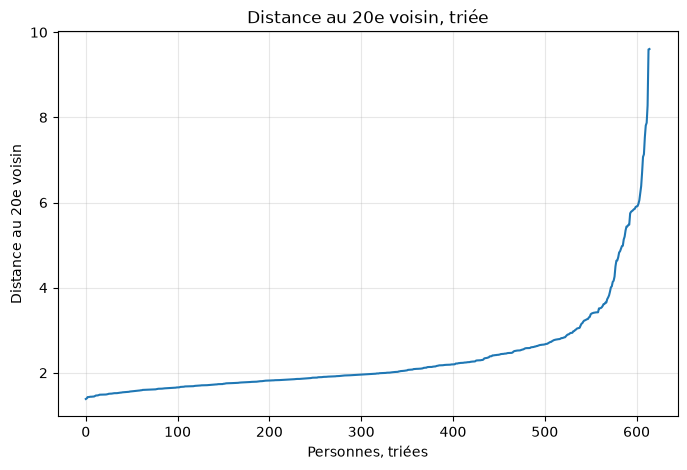

In [3]:
min_samples = 2 * X_scaled.shape[1]

voisins = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances_k, _ = voisins.kneighbors(X_scaled)
k_distances = np.sort(distances_k[:, -1])

plt.plot(k_distances)
plt.title(f"Distance au {min_samples}e voisin, triée")
plt.xlabel("Personnes, triées")
plt.ylabel(f"Distance au {min_samples}e voisin")
plt.savefig("figures/5_k_distances.png", dpi=150)
plt.show()

In [4]:
# Quantiles des k-distances, pour situer le coude avec des chiffres
pd.Series(k_distances).describe(percentiles=[0.5, 0.8, 0.9, 0.95, 0.99])

count   615.000
mean      2.343
std       1.125
min       1.385
50%       1.964
80%       2.628
90%       3.406
95%       4.935
99%       7.125
max       9.606
dtype: float64

### Lecture des résultats

- La courbe forme un plateau de 1,4 à environ 2,7 pour 80 % des personnes (zones denses), puis un coude entre 2,7 et 3,4, puis une montée brutale jusqu'à 9,6 (personnes isolées).
- **Décision : eps = 3,0**, au début du coude, dernière valeur avant d'inclure les personnes isolées dans les voisinages. Environ 12 % des personnes ont une 20e distance supérieure à 3,0 : elles ne seront pas des points centraux.
- eps est choisi uniquement à partir de cette courbe, sans utiliser la vraie catégorie.

In [5]:
import time # Pour mesurer le temps de calcul

### 5.2 Modèle et points de bruit

Nous construisons DBSCAN avec eps = 3,0 et min_samples = 20, puis nous comptons les clusters et les points de bruit (étiquette −1).

In [6]:
eps = 3.0

debut = time.time()
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels_dbscan = dbscan.fit_predict(X_scaled)
temps_dbscan = time.time() - debut

pd.Series(labels_dbscan).value_counts().rename(index={-1: "bruit"})

0        570
bruit     45
Name: count, dtype: int64

Nous vérifions si les points de bruit de DBSCAN correspondent au groupe atypique de 42 personnes trouvé par Ward. Ce sont deux méthodes très différentes : un accord renforcerait l'idée que ces personnes sont réellement à part.

In [7]:
pd.crosstab(labels_dbscan, labels["cah_ward"].values,
            rownames=["DBSCAN"], colnames=["Ward"])

Ward,1,2,3
DBSCAN,,,
-1,33,4,8
0,9,395,166


### Lecture des résultats

- DBSCAN trouve un seul cluster de 570 personnes et 45 points de bruit (7,3 %) : une zone dense entourée de personnes isolées, comme le laissait prévoir la densité inégale des données.
- 33 des 45 points de bruit appartiennent au groupe atypique de Ward, et 33 des 42 membres de ce groupe sont du bruit pour DBSCAN.
- Trois méthodes de principes différents (K-Means, Ward, DBSCAN) isolent donc le même noyau de personnes atypiques.

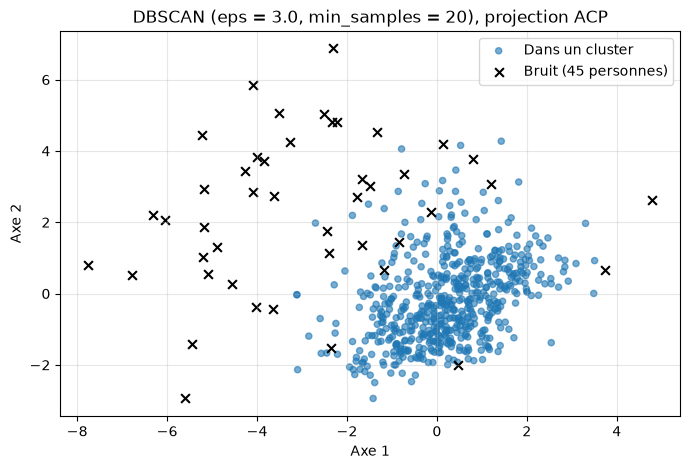

In [8]:
X_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_scaled)
bruit = labels_dbscan == -1

plt.scatter(X_2d[~bruit, 0], X_2d[~bruit, 1], s=20, alpha=0.6,
            c=labels_dbscan[~bruit], cmap="tab10", label="Dans un cluster")
plt.scatter(X_2d[bruit, 0], X_2d[bruit, 1], s=40, c="black", marker="x",
            label=f"Bruit ({bruit.sum()} personnes)")
plt.title(f"DBSCAN (eps = {eps}, min_samples = {min_samples}), projection ACP")
plt.xlabel("Axe 1")
plt.ylabel("Axe 2")
plt.legend()
plt.savefig("figures/5_dbscan.png", dpi=150)
plt.show()

Les points de bruit se concentrent dans la queue gauche du nuage, la même zone que le groupe atypique de Ward (voir notebook 2, section 4.6). Les quelques points de bruit au milieu du nuage sont isolés dans des dimensions que la projection ne montre pas.

### 5.3 Sensibilité à eps

Le choix de eps est délicat. Nous vérifions comment le nombre de clusters et de points de bruit évolue autour de la valeur choisie, pour savoir si le résultat est stable ou s'il dépend fortement de ce réglage.

In [9]:
sensibilite = []

for e in [2.0, 2.5, 3.0, 3.5, 4.0, 5.0]:
    lab = DBSCAN(eps=e, min_samples=min_samples).fit_predict(X_scaled)
    sensibilite.append({"eps": e,
                        "n_clusters": len(set(lab) - {-1}),
                        "n_bruit": int((lab == -1).sum())})

pd.DataFrame(sensibilite).set_index("eps")

,n_clusters,n_bruit
eps,,
2.000,1,136
2.500,1,75
3.000,1,45
3.500,1,34
4.000,1,27
5.000,1,10


### Lecture des résultats

- Pour eps entre 2 et 5, DBSCAN trouve toujours un seul cluster : la structure « zone dense et périphérie » est stable.
- Le nombre de points de bruit baisse régulièrement (de 136 à 10) sans palier net : il n'y a pas de frontière naturelle entre profils normaux et atypiques, on passe progressivement de l'un à l'autre.
- **Décision** : DBSCAN n'est pas utilisé pour former des groupes, mais comme détecteur d'anomalies. Nous gardons eps = 3,0 pour la vérification avec la vraie catégorie.

### 5.4 Sauvegarde

Avec un seul cluster, la silhouette, l'indice de Dunn et l'inertie ne sont pas définis : ils comparent la cohésion dans un groupe et la séparation entre groupes. Traiter le bruit comme un groupe serait trompeur, car il n'est pas compact. Ces valeurs sont donc laissées vides, et nous ajoutons le nombre de points de bruit.

In [10]:
labels["dbscan"] = labels_dbscan
labels.to_csv("resultats/labels.csv")

ligne_dbscan = pd.DataFrame({"K": 1,
                             "inertie": np.nan,
                             "silhouette": np.nan,
                             "dunn": np.nan,
                             "CPCC": np.nan,
                             "temps_s": temps_dbscan,
                             "n_bruit": int((labels_dbscan == -1).sum())},
                            index=pd.Index(["DBSCAN"], name="methode"))

metriques = pd.concat([metriques.drop("DBSCAN", errors="ignore"), ligne_dbscan])
metriques.to_csv("resultats/metriques.csv")
metriques

,K,inertie,silhouette,dunn,temps_s,CPCC,n_bruit
methode,,,,,,,
K-Means,3,4545.274,0.165,0.058,0.121,NaN,NaN
CAH Saut minimum,3,5772.645,0.592,0.406,0.004,0.865,NaN
CAH Saut maximum,3,5147.192,0.456,0.113,0.006,0.769,NaN
CAH Lien moyen,3,5730.736,0.578,0.404,0.005,0.868,NaN
CAH Ward,3,4779.017,0.147,0.051,0.006,0.541,NaN
DBSCAN,1,NaN,NaN,NaN,0.021,NaN,45.000


### Bilan de DBSCAN

- Avec min_samples = 20 et eps = 3,0 (choisi par le graphique des k-distances), DBSCAN trouve un seul cluster de 570 personnes et 45 points de bruit.
- Ce résultat est stable : un seul cluster pour toute valeur de eps entre 2 et 5. Seul le nombre de points de bruit varie, sans frontière naturelle.
- Le bruit recouvre largement le groupe atypique de Ward (33 personnes en commun) : DBSCAN confirme l'existence d'un noyau de profils atypiques.
- DBSCAN est ici un détecteur d'anomalies plutôt qu'une méthode de regroupement.

<a id="partie6"></a>
## Partie 6 : Évaluation

**Objectif** : comparer toutes les méthodes, puis vérifier pour la première fois si les groupes séparent les donneurs sains des malades.

**Principe** : deux types d'évaluation. Les indices internes (inertie, silhouette, Dunn, CPCC) sont calculés sans la catégorie : ils mesurent la forme des groupes. La validation externe compare les groupes à la vraie catégorie, avec des tableaux croisés.

**Hypothèses et paramètres** : la catégorie sert de référence pour l'état de santé. Mais le clustering ne cherche pas à la retrouver : il n'y a aucune raison d'obtenir autant de groupes que de catégories. Les 7 donneurs suspects sont des cas limites et sont signalés à part.

**Démarche** : tableau de comparaison des méthodes ; tableaux croisés à K = 3 ; examen de K = 2 ; test de l'hypothèse du sexe.

**Ce qui pourrait invalider le résultat** : le déséquilibre des catégories rend les pourcentages globaux trompeurs. Un groupe qui contiendrait tout le monde serait « juste » pour 87 % des personnes, puisque 87 % sont des donneurs. Nous regardons donc surtout la part des malades réunis dans un même groupe, et la composition de ce groupe.

### 6.1 Tableau de comparaison des méthodes

In [11]:
metriques[["K", "n_bruit", "inertie", "silhouette", "dunn", "CPCC", "temps_s"]]

,K,n_bruit,inertie,silhouette,dunn,CPCC,temps_s
methode,,,,,,,
K-Means,3,NaN,4545.274,0.165,0.058,NaN,0.121
CAH Saut minimum,3,NaN,5772.645,0.592,0.406,0.865,0.004
CAH Saut maximum,3,NaN,5147.192,0.456,0.113,0.769,0.006
CAH Lien moyen,3,NaN,5730.736,0.578,0.404,0.868,0.005
CAH Ward,3,NaN,4779.017,0.147,0.051,0.541,0.006
DBSCAN,1,45.000,NaN,NaN,NaN,NaN,0.021


### Lecture des résultats

- La silhouette, l'indice de Dunn et le CPCC placent en tête le saut minimum et le lien moyen, qui isolent pourtant seulement 4 ou 5 personnes. Ces indices récompensent la mise à l'écart des valeurs extrêmes.
- L'inertie est le seul indice cohérent avec la taille des groupes : K-Means (4545) est en tête, suivi de Ward (4779).
- Parmi les méthodes qui forment de vrais groupes, K-Means fait légèrement mieux que Ward sur tous les indices.
- DBSCAN ne se compare pas sur ces indices (un seul cluster), son rôle est la détection de 45 profils atypiques.
- Les temps de calcul sont tous négligeables.
- **Décision** : les indices internes ne permettent pas de choisir. La validation avec la vraie catégorie (6.2) est indispensable. Nous la faisons pour les 4 méthodes qui forment de vrais groupes ou isolent des profils : K-Means, Ward, saut maximum et DBSCAN.

### 6.2 Clusters face à la vraie catégorie (K = 3)

Pour la première fois, nous chargeons la vraie catégorie des personnes. Tous les clusters ont déjà été construits sans elle.

Pour chaque méthode, nous regardons deux choses :
- le tableau croisé détaillé (groupes × 5 catégories), pour voir où vont les malades selon leur stade ;
- une synthèse pour le groupe le plus riche en malades : quelle part de tous les malades il réunit, et quelle part de ses membres sont des malades.

In [12]:
# Chargement de la catégorie

categories = pd.read_csv("resultats/categories.csv", index_col=0)["Category"]

noms_courts = {"0=Blood Donor": "Donneur",
               "0s=suspect Blood Donor": "Suspect",
               "1=Hepatitis": "Hépatite",
               "2=Fibrosis": "Fibrose",
               "3=Cirrhosis": "Cirrhose"}
categorie = categories.map(noms_courts)

# Statut simplifié : les suspects restent à part
statut = categorie.replace({"Hépatite": "Malade", "Fibrose": "Malade", "Cirrhose": "Malade"})

statut.value_counts()

Category
Donneur    533
Malade      75
Suspect      7
Name: count, dtype: int64

In [13]:
ordre = ["Donneur", "Suspect", "Hépatite", "Fibrose", "Cirrhose"]

def tableau_croise(colonne):
    """Groupes d'une méthode croisés avec les 5 catégories, avec les totaux."""
    tableau = pd.crosstab(labels[colonne], categorie, margins=True, margins_name="Total")
    return tableau[ordre + ["Total"]]

In [14]:
tableau_croise("kmeans")

Category,Donneur,Suspect,Hépatite,Fibrose,Cirrhose,Total
kmeans,,,,,,
0,223,1,16,18,4,262
1,310,3,6,3,0,322
2,0,3,2,0,26,31
Total,533,7,24,21,30,615


In [15]:
tableau_croise("cah_ward")

Category,Donneur,Suspect,Hépatite,Fibrose,Cirrhose,Total
cah_ward,,,,,,
1,12,6,1,0,23,42
2,378,0,12,8,1,399
3,143,1,11,13,6,174
Total,533,7,24,21,30,615


In [16]:
tableau_croise("cah_complete")

Category,Donneur,Suspect,Hépatite,Fibrose,Cirrhose,Total
cah_complete,,,,,,
1,2,4,0,0,0,6
2,521,1,22,21,7,572
3,10,2,2,0,23,37
Total,533,7,24,21,30,615


In [17]:
tableau_croise("dbscan")

Category,Donneur,Suspect,Hépatite,Fibrose,Cirrhose,Total
dbscan,,,,,,
-1,6,7,6,2,24,45
0,527,0,18,19,6,570
Total,533,7,24,21,30,615


### Lecture des résultats

- Dans les 4 méthodes, le groupe atypique contient surtout des cirrhoses : 26 sur 30 pour K-Means, 24 pour DBSCAN, 23 pour Ward et pour le saut maximum.
- Le groupe atypique de K-Means ne contient aucun donneur sain : 26 cirrhoses, 2 hépatites et 3 suspects.
- Les hépatites et les fibroses restent en majorité mêlées aux donneurs. Aux stades précoces, le foie fonctionne encore et les analyses changent peu. À la cirrhose, plusieurs analyses changent en même temps, ce qui forme un profil distinct.
- Les grands groupes montrent un gradient : le groupe intermédiaire de K-Means contient 13 % d'hépatites et de fibroses, contre 3 % dans le groupe principal (14 % contre 5 % pour Ward).
- Les donneurs suspects ont des analyses réellement anormales : DBSCAN les classe tous les 7 en bruit, Ward en met 6 dans son groupe atypique.

Pour résumer, nous repérons pour chaque méthode le groupe qui contient la plus forte proportion de malades, puis nous calculons :
- **la part des malades réunis** : nombre de malades dans ce groupe divisé par le total des malades (75). Elle répond à la question « combien de malades le groupe retrouve-t-il ? » ;
- **la pureté** : nombre de malades dans ce groupe divisé par sa taille. Elle répond à la question « ce groupe contient-il surtout des malades ? ».

Un bon groupe doit être bon sur les deux mesures : réunir presque tous les malades dans un groupe énorme ne prouve rien, et un groupe très pur mais minuscule en rate beaucoup.

In [18]:
methodes = {"K-Means": "kmeans",
            "CAH Ward": "cah_ward",
            "CAH Saut maximum": "cah_complete",
            "DBSCAN (bruit)": "dbscan"}

synthese = []
for nom, colonne in methodes.items():
    t = pd.crosstab(labels[colonne], statut)
    groupe = (t["Malade"] / t.sum(axis=1)).idxmax()   # groupe le plus riche en malades
    synthese.append({"methode": nom,
                     "groupe": groupe,
                     "taille": t.loc[groupe].sum(),
                     "malades": t.loc[groupe, "Malade"],
                     "part_malades_reunis_%": 100 * t.loc[groupe, "Malade"] / t["Malade"].sum(),
                     "purete_%": 100 * t.loc[groupe, "Malade"] / t.loc[groupe].sum()})

pd.DataFrame(synthese).set_index("methode").round(1)

,groupe,taille,malades,part_malades_reunis_%,purete_%
methode,,,,,
K-Means,2,31,28,37.300,90.300
CAH Ward,1,42,24,32.000,57.100
CAH Saut maximum,3,37,25,33.300,67.600
DBSCAN (bruit),-1,45,32,42.700,71.100


### Lecture des résultats

| Méthode | Taille | Malades réunis | Pureté |
|---|---|---|---|
| K-Means | 31 | 37,3 % | 90,3 % |
| DBSCAN (bruit) | 45 | 42,7 % | 71,1 % |
| Saut maximum | 37 | 33,3 % | 67,6 % |
| Ward | 42 | 32,0 % | 57,1 % |

- K-Means forme le groupe le plus pur : 90 % de malades, et aucun donneur sain (les 3 autres membres sont des suspects).
- DBSCAN réunit le plus de malades, au prix d'une pureté plus faible.
- Aucune méthode ne réunit plus de 43 % des malades, car les stades précoces ressemblent aux donneurs.
- **Réponse à la question du projet** : les analyses de sang seules permettent de retrouver un groupe de personnes atteintes de cirrhose, presque sans erreur. Elles ne permettent pas de séparer les stades précoces (hépatite, fibrose) des donneurs sains par une méthode non supervisée.
- Le classement des méthodes s'inverse par rapport aux indices internes : la meilleure méthode selon la silhouette (saut minimum) serait inutile ici, alors que K-Means, moyen sur les indices, donne le groupe le plus pertinent médicalement.

In [19]:
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster

### 6.3 Et avec K = 2 ?

La silhouette de Ward était bien meilleure à K = 2 (0,47) qu'à K = 3 (0,15). Nous vérifions ce que deviennent les groupes à K = 2 face à la vraie catégorie. Pour Ward, seuls les deux grands groupes fusionnent, le groupe atypique ne change pas. Pour K-Means, le découpage peut changer entièrement.

In [20]:
kmeans_k2 = KMeans(n_clusters=2, init="k-means++", n_init=10,
                   random_state=SEED).fit_predict(X_scaled)

pd.crosstab(kmeans_k2, categorie.values,
            rownames=["K-Means K=2"], colnames=["Catégorie"])[ordre]

Catégorie,Donneur,Suspect,Hépatite,Fibrose,Cirrhose
K-Means K=2,,,,,
0,312,4,7,3,16
1,221,3,17,18,14


In [21]:
ward_k2 = fcluster(linkage(X_scaled, method="ward"), 2, criterion="maxclust")

pd.crosstab(ward_k2, categorie.values,
            rownames=["Ward K=2"], colnames=["Catégorie"])[ordre]

Catégorie,Donneur,Suspect,Hépatite,Fibrose,Cirrhose
Ward K=2,,,,,
1,12,6,1,0,23
2,521,1,23,21,7


### Lecture des résultats

- K-Means à K = 2 coupe la population en deux blocs de tailles proches (342 et 273), tous deux mélangés : les cirrhoses se répartissent entre les deux (16 et 14). Avec seulement 2 groupes, K-Means préfère couper la grande masse plutôt qu'isoler un petit groupe.
- Ward à K = 2 garde son groupe atypique de 42 personnes face à 573 autres : c'est cette séparation qui explique sa silhouette élevée à K = 2.
- **Décision** : K = 3 est nécessaire pour que K-Means isole les cirrhoses. Il est justifié à la fois par les indices et par l'utilité médicale.

### 6.4 Hypothèse du sexe

Les deux grands groupes (K-Means groupes 0 et 1, Ward groupes de 399 et 174) se chevauchent, et ne sont qu'en partie expliqués par les malades précoces. Certaines analyses dépendent naturellement du sexe : la créatinine et la cholinestérase sont en moyenne plus élevées chez les hommes. Le sexe n'a pas été utilisé pour le clustering, mais il pourrait expliquer ce découpage.

Pour isoler cet effet, nous regardons seulement les donneurs sains, et la proportion d'hommes et de femmes dans chaque groupe.

In [22]:
sexe = pd.read_csv("hcvdat0.csv", index_col=0)["Sex"]
donneurs = categorie == "Donneur"

pd.crosstab(labels.loc[donneurs, "kmeans"], sexe[donneurs],
            normalize="index").mul(100).round(1)

Sex,f,m
kmeans,,
0,19.300,80.700
1,55.500,44.500


In [23]:
pd.crosstab(labels.loc[donneurs, "cah_ward"], sexe[donneurs],
            normalize="index").mul(100).round(1)

Sex,f,m
cah_ward,,
1,50.000,50.000
2,50.000,50.000
3,14.000,86.000


### Lecture des résultats

- Chez les donneurs sains, le groupe intermédiaire compte 80,7 % d'hommes pour K-Means (contre 44,5 % dans le groupe principal), et 86 % pour Ward (contre 50 %).
- Le clustering n'a jamais utilisé la colonne Sex, mais il la retrouve en partie à travers les analyses qui en dépendent naturellement, comme la créatinine et la cholinestérase.
- La coupe de la masse principale est donc en bonne partie biologique (profils masculins et féminins normaux), et non médicale. Le léger enrichissement en hépatites et fibroses du groupe intermédiaire doit être interprété avec prudence.
- **Limite et piste d'amélioration** : standardiser les analyses séparément pour les hommes et pour les femmes retirerait cet effet, et laisserait peut-être apparaître d'autres groupes.

<a id="partie7"></a>
## Partie 7 : Analyse et conclusion

**Objectif** : décrire ce qui distingue chaque groupe sur le plan médical, évaluer la qualité de chaque groupe, puis conclure.

**Principe** : nous calculons les valeurs typiques de chaque analyse dans chaque groupe, en unités réelles pour la lecture médicale, et en écarts à la moyenne pour comparer les analyses entre elles. Nous mesurons ensuite la silhouette de chaque personne.

**Hypothèses et paramètres** : méthode retenue, K-Means avec K = 3 (meilleur groupe atypique, sans aucun donneur sain, et confirmé par Ward et DBSCAN). Nous utilisons la médiane pour les valeurs réelles, car elle n'est pas influencée par les valeurs extrêmes.

**Démarche** : profils des groupes et nom métier, silhouette par groupe, conclusion.

**Ce qui pourrait invalider le résultat** : un nom métier ne doit pas dépasser ce que montrent les chiffres. Le groupe intermédiaire, en particulier, est en grande partie expliqué par le sexe (voir 6.4).

### 7.1 Profils des clusters

Le tableau donne la médiane de chaque analyse dans chaque groupe, en unités réelles, avec la médiane de l'ensemble comme référence.

In [24]:
profils = X_brut.groupby(labels["kmeans"]).median()
profils.loc["Ensemble"] = X_brut.median()
profils.round(1)

,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
kmeans,,,,,,,,,,
0,44.400,69.200,34.400,31.000,9.200,9.400,5.700,82.000,34.800,75.000
1,40.400,62.200,18.300,22.400,6.000,7.500,5.100,72.000,16.600,70.800
2,32.000,84.000,5.900,95.400,37.000,3.600,3.900,72.300,105.600,69.100
Ensemble,42.000,66.200,23.000,25.900,7.300,8.300,5.300,77.000,23.300,72.200


La carte de chaleur montre l'écart de chaque groupe à la moyenne, en écarts types (données après log et standardisation). Rouge : analyse plus élevée que la moyenne. Bleu : plus basse. Cela permet de comparer les 10 analyses sur la même échelle, sans perte d'information.

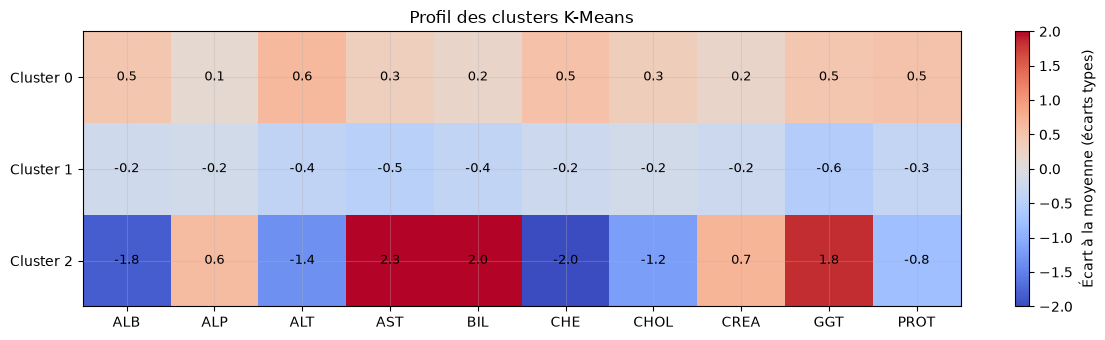

In [25]:
moyennes = X_scaled.groupby(labels["kmeans"]).mean()

plt.figure(figsize=(12, 3.5))
plt.imshow(moyennes, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
plt.colorbar(label="Écart à la moyenne (écarts types)")
plt.xticks(range(len(analyses)), analyses)
plt.yticks(range(len(moyennes)), [f"Cluster {c}" for c in moyennes.index])

for i in range(moyennes.shape[0]):
    for j in range(moyennes.shape[1]):
        plt.text(j, i, f"{moyennes.iloc[i, j]:.1f}", ha="center", va="center", fontsize=9)

plt.title("Profil des clusters K-Means")
plt.tight_layout()
plt.savefig("figures/7_profils_kmeans.png", dpi=150)
plt.show()

### 7.2 Qualité de chaque cluster

La silhouette moyenne (0,165) cache des différences entre groupes. Pour chaque personne, une silhouette proche de 1 indique qu'elle est bien dans son groupe. Une silhouette négative indique qu'elle serait plus proche d'un autre groupe.

In [26]:
s = silhouette_samples(X_scaled, labels["kmeans"])

pd.DataFrame({"cluster": labels["kmeans"].values, "silhouette": s}) \
  .groupby("cluster")["silhouette"] \
  .agg(taille="size", moyenne="mean", part_negative=lambda x: 100 * (x < 0).mean()) \
  .round(2)

,taille,moyenne,part_negative
cluster,,,
0,262,0.120,10.690
1,322,0.210,0.000
2,31,0.060,29.030


### Lecture des résultats

| Cluster | Taille | Silhouette moyenne | Personnes mal placées |
|---|---|---|---|
| 1 (bilan normal, valeurs basses) | 322 | 0,21 | 0 % |
| 0 (bilan normal, valeurs hautes) | 262 | 0,12 | 10,7 % (environ 28) |
| 2 (profil de cirrhose) | 31 | 0,06 | 29 % (9 personnes) |

- Le cluster 1 est le plus compact : aucune personne mal placée.
- Les personnes mal placées du cluster 0 sont à la frontière avec le cluster 1, comme l'avaient montré les désaccords entre K-Means et Ward.
- Le cluster 2 est le plus pertinent médicalement (26 cirrhoses, aucun donneur sain), mais le moins compact : les cirrhoses n'ont pas toutes la même gravité, leurs analyses sont très dispersées. Elles restent cependant toutes éloignées des bilans normaux.
- Un groupe peut donc être médicalement très juste et géométriquement peu compact : la silhouette seule ne suffit pas pour juger un clustering.

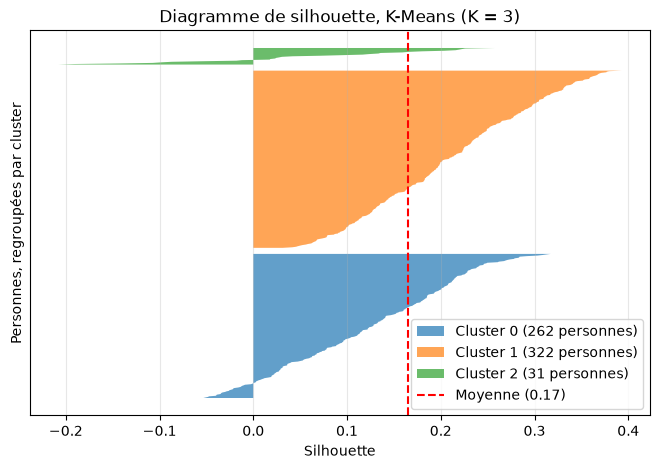

In [27]:
y_bas = 10
for c in sorted(labels["kmeans"].unique()):
    valeurs = np.sort(s[labels["kmeans"].values == c])
    plt.fill_betweenx(np.arange(y_bas, y_bas + len(valeurs)), 0, valeurs,
                      alpha=0.7, label=f"Cluster {c} ({len(valeurs)} personnes)")
    y_bas += len(valeurs) + 10

plt.axvline(s.mean(), color="red", linestyle="--", label=f"Moyenne ({s.mean():.2f})")
plt.title("Diagramme de silhouette, K-Means (K = 3)")
plt.xlabel("Silhouette")
plt.ylabel("Personnes, regroupées par cluster")
plt.yticks([])
plt.legend()
plt.savefig("figures/7_silhouette_kmeans.png", dpi=150)
plt.show()

In [28]:
profils.round(1).to_csv("resultats/profils_kmeans.csv")

### 7.3 Conclusion

#### Réponse à la question du projet

À partir des seules analyses de sang, sans jamais utiliser la catégorie, les méthodes de clustering retrouvent un groupe de personnes atteintes de cirrhose. Avec K-Means, ce groupe réunit 26 des 30 cirrhoses et ne contient aucun donneur sain. En revanche, les stades précoces (hépatite, fibrose) ne se distinguent pas des donneurs : aux stades précoces, le foie fonctionne encore et les analyses changent peu. Au total, aucune méthode ne réunit plus de 43 % des malades.

#### Méthode retenue : K-Means avec K = 3

- K = 3 est indiqué par le coude et la silhouette de K-Means, et par le plus grand écart de hauteur de Ward. Il est aussi nécessaire en pratique : à K = 2, K-Means perd le groupe des cirrhoses.
- Parmi les méthodes qui forment de vrais groupes, K-Means a les meilleurs indices internes (inertie, silhouette, Dunn).
- Son groupe atypique est le plus pur (90 % de malades, aucun donneur sain).
- Ce groupe est confirmé par deux méthodes de principes différents : Ward (80 % d'accord avec K-Means) et DBSCAN (son bruit recouvre le même noyau).
- La CAH avec le critère de Ward reste une bonne alternative, avec l'avantage du dendrogramme. DBSCAN est utile en complément pour signaler les profils isolés.

#### Ce que nous avons appris sur les méthodes

- Les indices internes ne suffisent pas pour choisir : la silhouette, l'indice de Dunn et le CPCC favorisaient le saut minimum, qui isole seulement 4 personnes. Il faut toujours regarder la taille et la composition des groupes.
- L'effet de chaîne du saut minimum et la préférence de K-Means et de Ward pour des groupes de tailles proches se sont vérifiés sur nos données.
- La préparation était déterminante : sans standardisation, les distances ne dépendaient presque que de la créatinine et de la GGT.
- Le groupe le plus utile médicalement (cirrhoses) est aussi le moins compact (silhouette de 0,06) : la qualité géométrique et la pertinence médicale ne coïncident pas toujours.

#### Limites

- Groupes très déséquilibrés (533 donneurs contre 75 malades) et peu de malades par stade (21 à 30) : impossible de former un groupe par stade.
- Silhouette faible (0,17) : les deux groupes normaux se chevauchent.
- Le découpage des personnes au bilan normal reflète en grande partie le sexe, et non la maladie.
- Données d'un seul hôpital : les résultats ne sont pas forcément généralisables.
- Le clustering est un outil d'exploration ou de repérage, pas un diagnostic.

#### Perspectives

- Standardiser les analyses séparément pour les hommes et pour les femmes, afin de retirer l'effet du sexe.
- Tester un modèle de mélange gaussien (GMM), qui accepte des groupes de formes et de tailles différentes.
- Avec la catégorie connue, une méthode supervisée serait plus adaptée pour distinguer les stades précoces.

### Réponse à la question de départ

*À partir de leurs seules analyses de sang, peut-on retrouver des groupes de personnes qui se ressemblent, et ces groupes séparent-ils les donneurs sains des patients malades du foie ?*

« Oui, les analyses de sang seules permettent de former des groupes, et l’un d’eux réunit presque toutes les cirrhoses sans aucun donneur sain. En revanche, les stades précoces de la maladie restent indiscernables des donneurs. Le clustering repère la maladie avancée, il ne la dépiste pas tôt. »